# 01 · Comprensión y auditoría de las imágenes H&M

**Pregunta:** ¿podemos construir un conjunto local de imágenes pequeño, trazable y adecuado para comparar Dense, CNN, LSTM y, si es viable, Transformer?

El objetivo es clasificar **tipos de prenda** a partir de fotografías de producto. En este notebook se estudian el origen y la taxonomía, se comprueban todas las imágenes y se justifica el conjunto de clases. No se entrena ningún modelo.

El profesor pide objetivos e hipótesis, EDA y experimentos que permitan entender las arquitecturas; las ablaciones son obligatorias. El notebook 02 prepara un protocolo común. El notebook 03 realizará el EDA detallado de entrenamiento y los baselines.

**Hipótesis para los futuros experimentos:** la estructura espacial favorecerá a CNN frente a Dense; transfer learning reducirá el coste de entrenamiento; clases próximas como `Sweater` y `Cardigan` serán difíciles de separar. Son hipótesis, no resultados comprobados.

> **Estado de ejecución verificado · 20/11/2026.** Ejecutado: todas las celdas de código tienen salidas sin errores. Las ablaciones de redes pendientes no se presentan como realizadas.

## Cómo interpretamos las pistas de clase: vías para desarrollar el proyecto

**Origen y alcance (20/11/2026).** Esta sección interpreta los apuntes aproximados de Iratxe sobre una explicación del profesor; no es una transcripción ni una nueva rúbrica. Los apuntes enlazaban «basic architectures (scratch)», «pre-trained / self-supervised», «word-vector / embedding», CNN, LSTM/GRU, attention, RNN, self-attention, Transformer y «don't look for performance». La anotación «BERT → auto-regressive model» se revisa conceptualmente abajo. No atribuimos al profesor una equivalencia que los apuntes, por sí solos, no permiten confirmar.

La idea que recogemos es **aprender mediante experimentos sencillos y comparaciones explicables**, sin convertir el proyecto en una carrera por la mejor accuracy. Hay varias vías y extensiones posibles; no hace falta implementar todas las combinaciones. Esto no elimina los mínimos del material docente ya consultado: Dense, CNN, LSTM, Transformer si es viable y ablaciones obligatorias.

| Vía | Qué se estudia | Encaje en este proyecto | Notebooks |
|---|---|---|---|
| Arquitecturas básicas desde cero (*scratch*) | Aprender los pesos partiendo de una inicialización aleatoria; entender optimización e inductive bias | Dense, CNN y LSTM/GRU sobre las mismas imágenes y grupos de producto | 04–06; mini-ViT en 08 si es viable |
| Reutilizar un modelo preentrenado | Extraer representaciones con pesos congelados y después comparar con fine-tuning | Es una vía habitual en visión aplicada. Distinguir pesos supervisados de pesos autosupervisados; documentar su origen | 07 y variante preentrenada de 08 |
| Estudiar representaciones y relaciones | Comprender embeddings, atención y estrategias de aprendizaje | CLIP conecta imagen y texto; una extensión NLP con las descripciones permitiría estudiar word vectors → CNN1D/RNN/Transformer | 11; extensión NLP opcional |
| Explorar generación | Aprender una distribución y producir muestras o secuencias nuevas | Autoencoder/VAE para visión; generación autorregresiva de texto solo como posible extensión | 12 |

Son ejes que se combinan, no categorías excluyentes: un Transformer puede entrenarse desde cero o reutilizarse; el preentrenamiento puede ser supervisado o autosupervisado; obtener un embedding no implica generar contenido.

**Decisión del proyecto.** El núcleo sigue siendo clasificación visual de prendas con los datos preparados en 02. Primero estudiaremos arquitecturas pequeñas y sus ablaciones; después, reutilización de representaciones. CLIP, NLP y generación se mantienen como ampliaciones explícitas según tiempo y recursos. Los notebooks 03–12 describen trabajo previsto: estas notas no significan que esos experimentos estén ejecutados.

**Vocabulario para leer los apuntes.** Un embedding es un vector que representa una palabra/token, una imagen o un parche. En NLP, los word vectors pueden alimentar una CNN1D, una RNN con LSTM/GRU o un Transformer. Una CNN aprende relaciones locales con convoluciones; una RNN transporta información mediante estados recurrentes. Añadir una capa de atención a una CNN o a una RNN es una opción arquitectónica, no una propiedad obligatoria. Self-attention relaciona posiciones de una misma secuencia; no es exclusiva de las RNN y es central en los Transformers. Los parches de una imagen pueden actuar como tokens visuales sin ser palabras.

**BERT frente a generación autorregresiva.** BERT original es un encoder Transformer bidireccional, preentrenado con predicción de tokens enmascarados y una tarea de relación entre frases. No es un modelo causal de siguiente token tipo GPT. Una interpretación posible de la flecha del apunte es el contraste o paso entre estas familias, no que sean equivalentes. Clasificar con embeddings de BERT tampoco equivale a generar texto. Los embeddings por sí mismos no son «GenAI».

**Cómo juzgaremos los experimentos.** Registrar hipótesis, qué componente se cambia y qué se mantiene fijo; observar curvas, errores por clase, coste y variación entre semillas. Las métricas sirven como evidencia, incluso cuando una arquitectura sencilla supera a otra más compleja. No es obligatorio que cada modelo nuevo mejore el anterior. Se diseña y ajusta con train/validation y se reserva test para la evaluación final.

**Referencias para verificar los conceptos, no para reconstruir las palabras exactas de clase:** [Word2Vec](https://arxiv.org/abs/1301.3781), [Transformer](https://arxiv.org/abs/1706.03762), [BERT](https://arxiv.org/abs/1810.04805), [SimCLR](https://arxiv.org/abs/2002.05709), [CLIP](https://arxiv.org/abs/2103.00020), [GPT-2](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf). Los requisitos docentes previamente consultados se documentan en `docs/requisitos-profesor.md`.


## Protocolo revisado antes del entrenamiento · 20/11/2026

La referencia común es `config/experimental_protocol_v1.json`. Es un diseño fijado antes de entrenar las redes, no una lista de resultados obtenidos. La versión equilibrada de 18.000 fotos se conserva como experimento exploratorio. Sus métricas describen las doce clases seleccionadas con ese muestreo; no estiman automáticamente el comportamiento sobre el catálogo original.

**Por defecto:** entropía cruzada sin pesos, sin aumentos y con normalización de train a la resolución de entrada. Pesos de clase y aumentos se activarán como ablaciones explícitas. Los pesos guardados en 02 son una opción calculada, no una instrucción de aplicarlos siempre. Cada experimento registrará resolución, preprocesamiento, IDs de productos, configuración, semilla y presupuesto.

**Métricas fijadas:** macro-F1 primaria; accuracy secundaria; precisión, recall, F1 y soporte por clase; matriz de confusión en recuentos y normalizada por filas. Comparar parámetros entrenables, tiempo de entrenamiento, latencia por imagen, memoria pico y hardware. Selección por macro-F1 de validation; early stopping por pérdida de validation; tres semillas (42, 123 y 2026). El test permanece cerrado hasta congelar decisiones; intervalos finales mediante remuestreo de grupos de producto, no imágenes independientes. Los baselines deterministas no necesitan simular tres entrenamientos diferentes.

### Límites de las decisiones de datos

La exclusión de `Top` y la inclusión de `Cardigan` son **decisiones exploratorias**, tomadas después de observar una muestra reservada. Dos ejemplos ilustran una posible heterogeneidad, pero no permiten medirla en toda la categoría ni demostrar que Cardigan sea una clase mejor. Shirt/T-shirt y Sweater/Cardigan también pueden solaparse: son hipótesis de confusión pendientes de EDA y revisión, no conclusiones ya establecidas.

No presentamos como establecidos de antemano criterios que se han introducido después. Para una versión futura: fijar ámbito de prendas, definición de cada clase, mínimo de grupos independientes y viabilidad de particiones; después aplicar el mismo procedimiento de revisión a todas las clases, incluyendo las ambiguas. La revisión inicial de Top deberá ampliarse con productos reservados fuera de todas las particiones antes de ratificar o modificar esa decisión. La revisión de train de 03 amplía el análisis de las clases actuales; no resuelve por sí sola la exclusión de Top.

El cupo de 1.500 por clase reduce de forma muy distinta cada categoría. No se describe como una muestra representativa. Se añadirá una ablación de equilibrio de entrenamiento y una sensibilidad de evaluación a prevalencias; ambas se distinguen en 09. Los 224×224 son el formato almacenado, no una obligación de entrada para todas las redes. No extraeremos conclusiones sobre dificultades visuales hasta desarrollar el EDA de 03.


## 1. Entorno y configuración explícita

Las clases, cupos, resolución, semilla y proporciones están en `config/local_images_v1.json`. La misma configuración alimenta los dos notebooks. Las rutas se resuelven desde el proyecto y los identificadores se conservan como texto, incluidos sus ceros iniciales.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data/data_contract.py').is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src/data'))
from notebook_utils import setup, styled, es, numeric_axis, save_figure, SPLIT_COLOURS, BLUE, ORANGE
setup()
config = json.loads((ROOT / 'config/local_images_v1.json').read_text(encoding='utf-8'))
SEED = config['seed']
display(Markdown(f"**Proyecto:** `{ROOT.name}` · **Python:** {platform.python_version()} · **Semilla:** {SEED}"))

**Proyecto:** `fashion-vision-dl` · **Python:** 3.12.2 · **Semilla:** 42

## 2. Auditoría completa y reanudable

`audit_images.py` verifica estructura y decodificación completa, orientación EXIF, dimensiones y modo de color. Calcula SHA-256 del fichero y de los píxeles RGB orientados: el primero identifica bytes y el segundo detecta imágenes idénticas aunque difieran sus metadatos. No detecta todos los duplicados aproximados.

La primera ejecución es costosa. Se guardan checkpoints cada mil archivos; una auditoría terminada se publica en `data/audit/runs/` y `data/audit/CURRENT.json`. Al reutilizarla se verifican checksums, metadatos, código e inventario del RAW si está conectado. Con el RAW desconectado se conserva el informe de la auditoría anterior; eso no verifica un origen externo que haya cambiado.

In [2]:
from audit_images import ensure_audit, read_audit
ensure_audit(workers=6)
audit_run, audit, summary = read_audit()
assert audit.article_id.is_unique
assert audit.article_id.str.fullmatch(r'\d+').all()
valid = audit.loc[audit.image_valid].copy()
inventory = pd.DataFrame({
    'Comprobación': ['Artículos en metadatos', 'Imágenes encontradas', 'Imágenes válidas',
                    'Imágenes corruptas/no admitidas', 'Artículos sin imagen', 'Imágenes sin metadatos',
                    'Filas repetidas por píxeles', 'Tamaño RAW (GB decimales)'],
    'Resultado': [summary['articles'], summary['images_found'], summary['images_valid'],
                  summary['images_invalid'], summary['missing_images'], summary['orphan_images'],
                  summary['duplicate_pixel_rows'], summary['raw_bytes']/1e9]
})
display(styled(inventory, 2))
display(Markdown(f"**Auditoría utilizada:** `{audit_run.relative_to(ROOT).as_posix()}`"))

Auditoría vigente verificada: C:\Iratxe\UPM\prdl y mllb\fashion-vision-dl\data\audit\runs\20261119T135142-10425e86


Comprobación,Resultado
Artículos en metadatos,"105.542,00"
Imágenes encontradas,"105.100,00"
Imágenes válidas,"105.100,00"
Imágenes corruptas/no admitidas,"0,00"
Artículos sin imagen,"442,00"
Imágenes sin metadatos,"0,00"
Filas repetidas por píxeles,"206,00"
Tamaño RAW (GB decimales),"30,56"


**Auditoría utilizada:** `data/audit/runs/20261119T135142-10425e86`

## 3. Enlace con los metadatos y calidad del origen

Cada nombre de archivo se enlaza con `article_id`. Una imagen ausente o inválida conserva su fila y un motivo de exclusión; nunca recibe una partición de modelado. No se interpreta una ausencia de foto como una característica de la prenda. El informe de imágenes huérfanas queda en la publicación de auditoría.

In [3]:
missing_by_class = audit.assign(sin_imagen=~audit.image_exists).groupby('product_type_name').agg(
    articulos=('article_id', 'size'), sin_imagen=('sin_imagen', 'sum')).sort_values('sin_imagen', ascending=False)
display(styled(missing_by_class.head(15)))
display(styled(audit[['width', 'height', 'file_bytes']].loc[audit.image_valid].describe(percentiles=[.05, .5, .95]).T, 1))
display(styled(valid.original_mode.value_counts().rename_axis('Modo original').to_frame('Imágenes')))
incidents = audit.loc[~audit.image_valid, ['article_id', 'product_type_name', 'reason']]
display(incidents.head(12))

Tipo de prenda,Artículos,Sin imagen
Sneakers,1.621,48
Sunglasses,621,46
Ballerinas,372,26
Sandals,757,24
T-shirt,7.904,24
Underwear bottom,2.748,23
Trousers,11.169,19
Necklace,581,18
Hair/alice band,854,18
Other accessories,1.034,17


,Número,Media,Desv. típica,Mínimo,5%,50%,95%,Máximo
width,105.100,"1.191,3","186,0","222,0","1.166,0","1.166,0","1.396,0","3.494,0"
height,105.100,"1.750,0","0,1","1.749,0","1.750,0","1.750,0","1.750,0","1.750,0"
file_bytes,105.100,"290.742,5","162.885,2","33.431,0","111.950,9","251.798,0","598.768,6","1.849.119,0"


Modo original,Imágenes
RGB,105.099
L,1


ID del artículo,Tipo de prenda,Motivo
0174057028,Pyjama jumpsuit/playsuit,missing_image
0179208001,Leggings/Tights,missing_image
0212042043,Sneakers,missing_image
0212042066,Sneakers,missing_image
0212629004,Dress,missing_image
0215324023,Sunglasses,missing_image
0216961011,Hair/alice band,missing_image
0218354021,Vest top,missing_image
0241602023,Blazer,missing_image
0268305006,Sunglasses,missing_image


## 4. Comparación de las taxonomías y elección del objetivo

`garment_group_name` combina material (`Jersey`, `Knitwear`), uso y secciones comerciales; `product_group_name` agrupa por zona corporal y resulta demasiado grueso para el objetivo propuesto. `product_type_name` ofrece nombres de objetos más directamente relacionados con la forma visual, aunque sigue teniendo clases próximas y posibles errores.

La siguiente medida de **pureza respecto al tipo** suma el tamaño del tipo mayoritario dentro de cada grupo y divide por el número de imágenes válidas. Describe cómo se mezclan los tipos en cada taxonomía; no mide precisión de un clasificador.

In [4]:
rows = []
for target in ['garment_group_name', 'product_group_name', 'product_type_name', 'index_group_name']:
    counts = valid[target].value_counts()
    cross = pd.crosstab(valid[target], valid.product_type_name)
    rows.append({'Objetivo': target, 'Clases': len(counts), 'Clase mayor (%)': 100*counts.iloc[0]/len(valid),
                 'Unknown (%)': 100*valid[target].eq('Unknown').mean(),
                 'Pureza respecto al tipo (%)': 100*cross.max(axis=1).sum()/len(valid)})
display(styled(pd.DataFrame(rows).set_index('Objetivo'), 2))
mixtures = pd.crosstab(valid.garment_group_name, valid.product_type_name)
example = pd.DataFrame({'Tipos distintos': mixtures.gt(0).sum(axis=1),
                        'Tipo mayoritario': mixtures.idxmax(axis=1),
                        'Pureza (%)': 100*mixtures.max(axis=1)/mixtures.sum(axis=1)})
display(styled(example.sort_values('Pureza (%)').head(10), 1))

Objetivo,Clases,Clase mayor (%),Unknown (%),Pureza respecto al tipo (%)
garment_group_name,21,"20,38","3,68","43,81"
product_group_name,19,"40,61","0,12","39,00"
product_type_name,131,"10,61","0,12","100,00"
index_group_name,5,"37,63","0,00","13,58"


Grupo de prendas,Tipos distintos,Tipo mayoritario,Pureza (%)
Accessories,"81,0",Bag,"11,0"
Unknown,"68,0",Trousers,"15,3"
Woven/Jersey/Knitted mix Baby,"39,0",Trousers,"22,0"
Jersey Fancy,"42,0",T-shirt,"23,8"
Jersey Basic,"17,0",T-shirt,"25,5"
Special Offers,"49,0",Dress,"26,1"
Shoes,"21,0",Sneakers,"31,3"
"Under-, Nightwear","35,0",Underwear bottom,"36,3"
Swimwear,"14,0",Swimwear bottom,"42,9"
Dresses/Skirts girls,"10,0",Dress,"46,2"


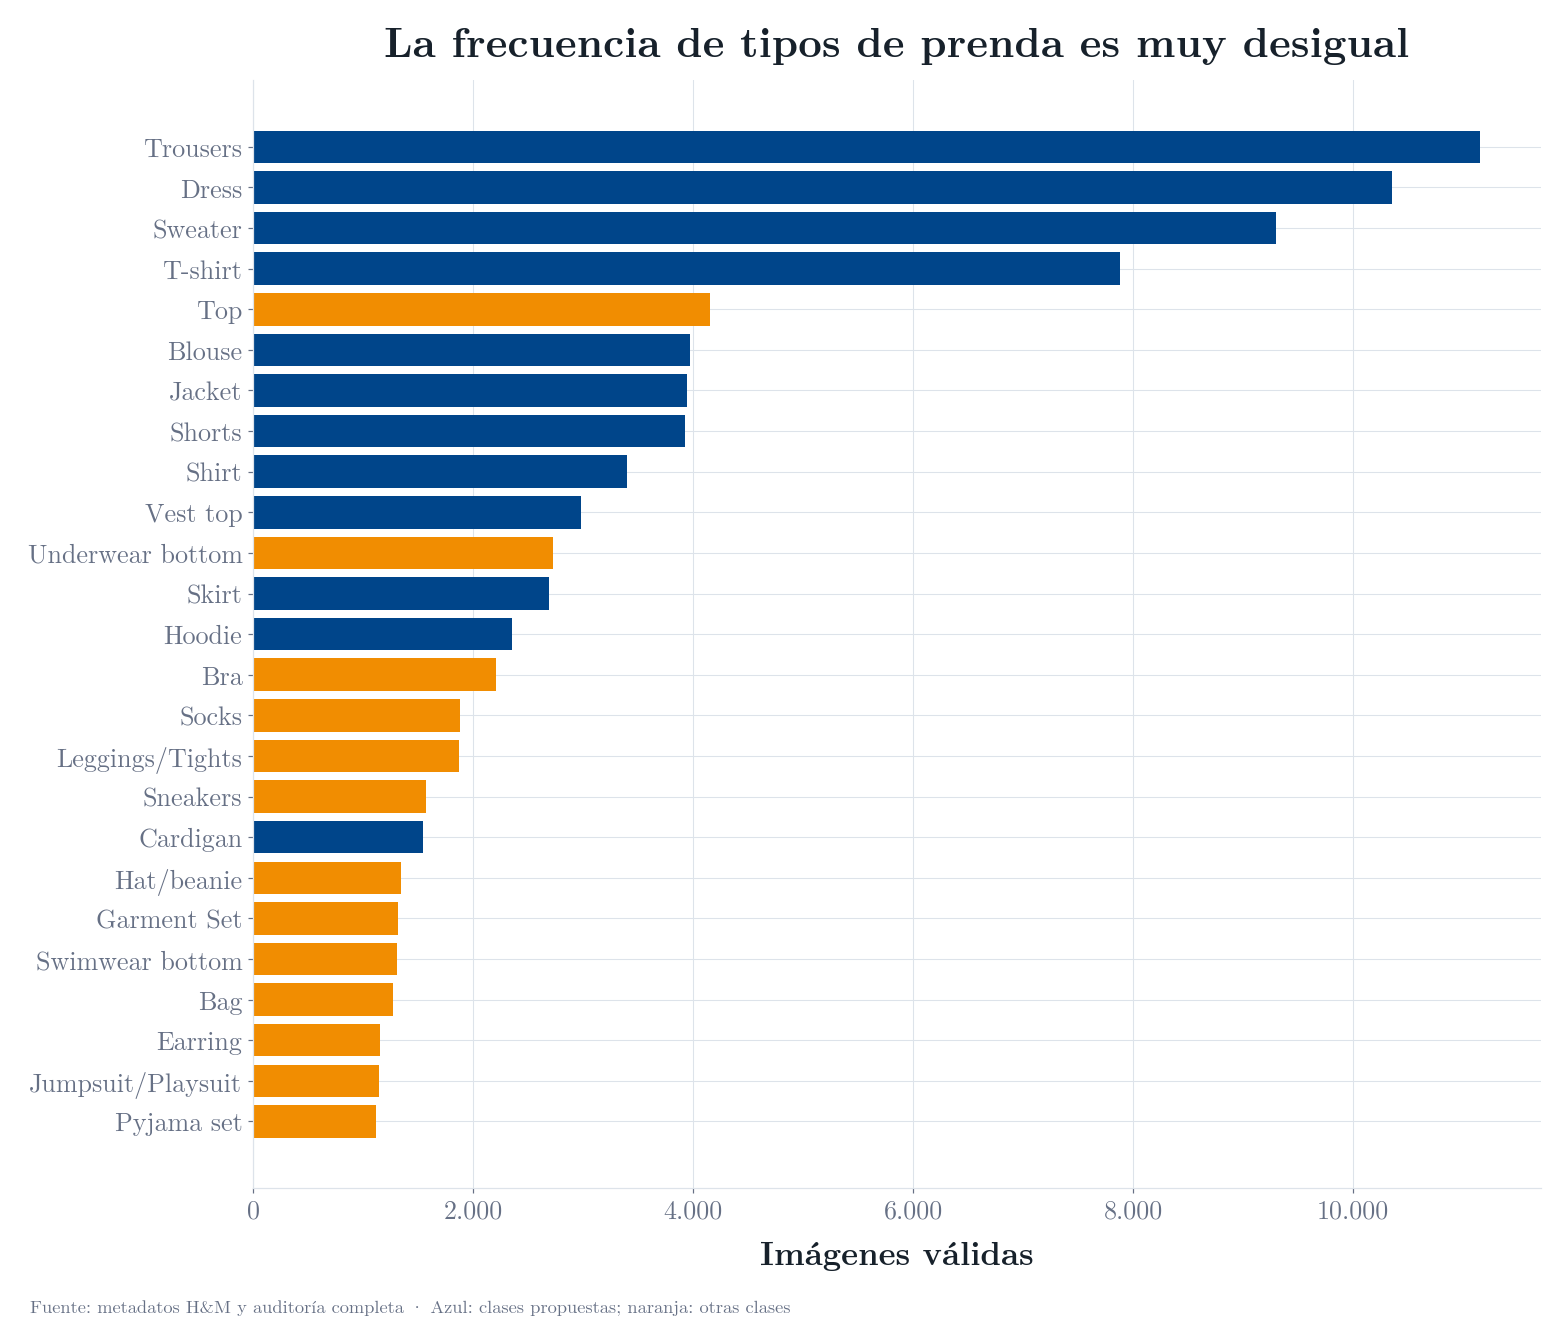

In [2]:
counts = valid.product_type_name.value_counts().head(25).sort_values()
fig, ax = plt.subplots(figsize=(14, 12))
colours = [BLUE if label in config['include_classes'] else ORANGE for label in counts.index]
ax.barh(counts.index, counts.values, color=colours)
ax.set(title='La frecuencia de tipos de prenda es muy desigual', xlabel='Imágenes válidas')
ax.xaxis.grid(True); ax.set_axisbelow(True); numeric_axis(ax)
save_figure(fig, ROOT, '01_product_types', 'Fuente: metadatos H&M y auditoría completa · Azul: clases propuestas; naranja: otras clases')
plt.show()

## 5. Resolución, proporciones y tamaño

La forma original no se debe deformar para convertir una imagen en cuadrada. Se propone redimensionar conservando la proporción y completar con fondo blanco hasta 224×224. Es una elección inicial de presupuesto que habrá que contrastar mediante ablaciones de resolución. La pérdida de detalles finos es una limitación explícita.

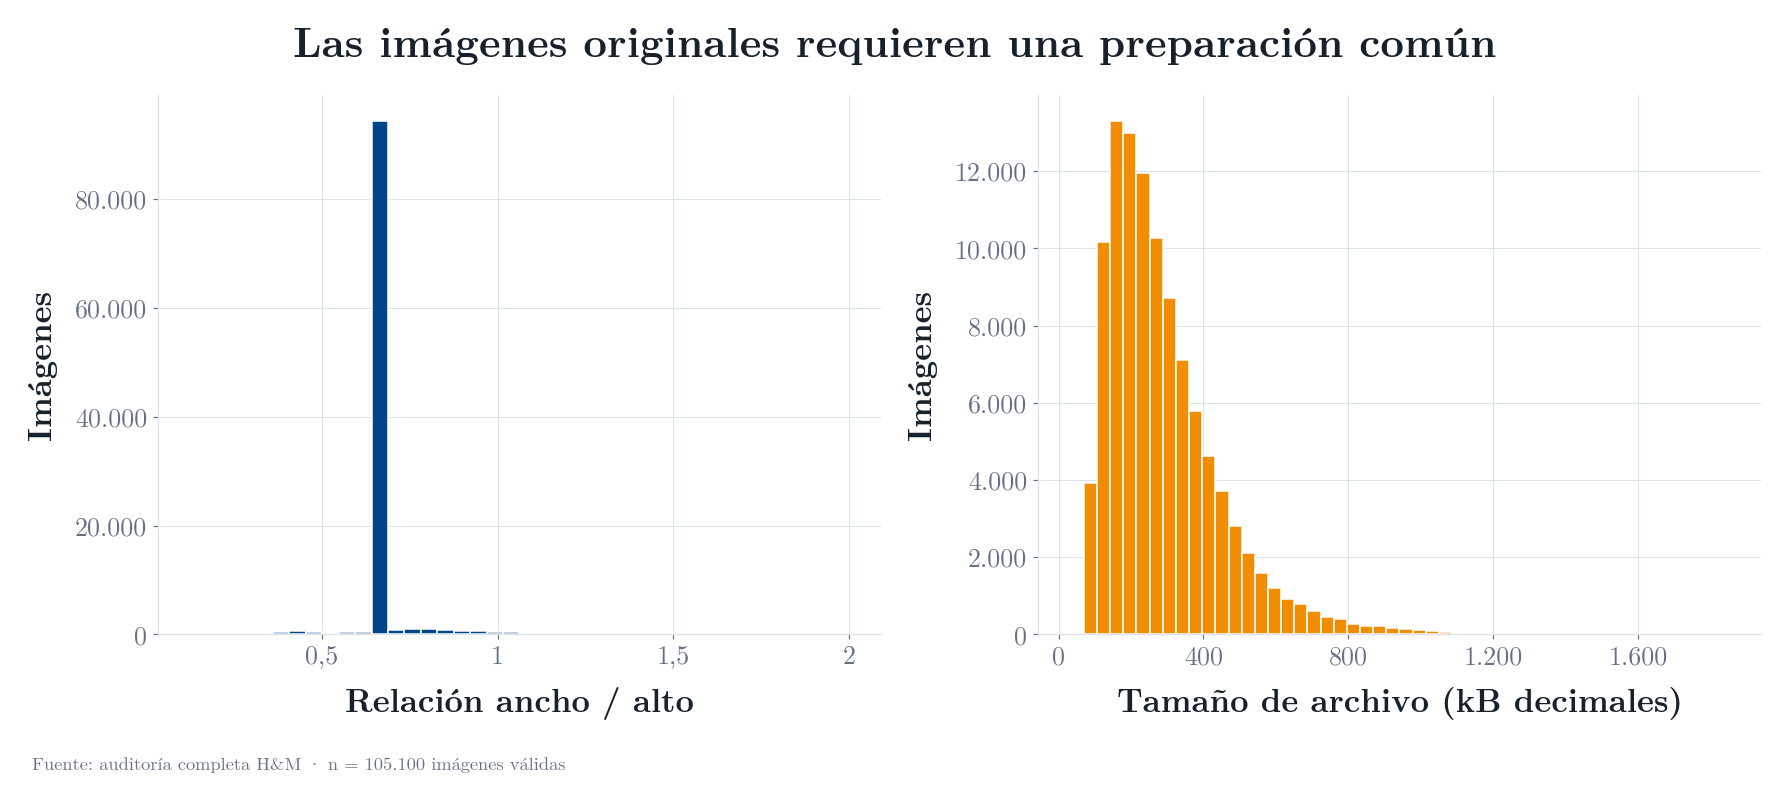

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(valid.width/valid.height, bins=40, color=BLUE, edgecolor='white')
axes[0].set(xlabel='Relación ancho / alto', ylabel='Imágenes')
axes[1].hist(valid.file_bytes/1000, bins=50, color=ORANGE, edgecolor='white')
axes[1].set(xlabel='Tamaño de archivo (kB decimales)', ylabel='Imágenes')
for ax in axes:
    ax.yaxis.grid(True); ax.set_axisbelow(True); numeric_axis(ax, 'y'); numeric_axis(ax, 'x', 1)
from matplotlib.ticker import MaxNLocator, FuncFormatter
from src.visualization.style import format_number
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: format_number(value)))
fig.suptitle('Las imágenes originales requieren una preparación común', weight='bold', fontsize=15)
save_figure(fig, ROOT, '01_image_properties', f'Fuente: auditoría completa H&M · n = {es(len(valid))} imágenes válidas')
plt.show()

## 6. Reglas de selección previas al modelado

Se proponen doce tipos frecuentes de prendas de vestir, suficientes para comparar arquitecturas con un presupuesto local acotado. Se excluyen accesorios, ropa interior y otras familias de este primer experimento para mantener un problema coherente; no se afirma que sus imágenes sean de mala calidad. `Top` se excluye exploratoriamente por la posible heterogeneidad observada en la reserva visual inicial (véase la discusión de la galería). Se incluye `Cardigan`, un tipo más específico con suficientes ejemplos. `Vest top` se mantiene como tipo de prenda de tirantes.

Las reglas se aplican en este orden: validez → clase elegida → lado mínimo de 64 píxeles → exclusión de grupos con etiquetas contradictorias → eliminación de duplicados exactos → reserva de dos grupos por clase para inspección visual → cupo de hasta 1.500 imágenes por clase mediante grupos completos. Deben quedar al menos 500 imágenes y grupos suficientes para tres particiones por clase.

Un grupo conecta transitivamente variantes del mismo `product_code` o imágenes de píxeles idénticos. La reserva visual y el cupo se determinan mediante hashes con semilla; cambiar el orden de los ficheros no cambia la selección. El cupo reduce el estudio a una muestra de clases aproximadamente equilibrada: no conserva la prevalencia natural del catálogo.

In [7]:
from prepare_local import select_candidates
selection, candidates = select_candidates(audit, config)
display(pd.Series(config, name='Configuración').to_frame())
selection_table = pd.DataFrame({'Válidas en origen': valid.product_type_name.value_counts(),
                                'Seleccionadas antes de preparar': candidates.label.value_counts()}).fillna(0).astype(int)
display(styled(selection_table.loc[config['include_classes']]))
display(styled(selection.exclusion_reason.replace('', 'candidate').value_counts().rename_axis('Motivo').to_frame('Artículos')))
assert candidates.groupby('label').size().le(config['max_images_per_class']).all()
assert set(candidates.label) == set(config['include_classes'])

,Configuración
preparation_version,1.0.0
target,product_type_name
include_classes,"[Trousers, Dress, Sweater, T-shirt, Cardigan, ..."
min_side,64
max_images_per_class,1500
min_class_images,500
image_size,224
jpeg_quality,90
padding_rgb,"[255, 255, 255]"
seed,42


,Válidas en origen,Seleccionadas antes de preparar
Trousers,11.150,1.500
Dress,10.348,1.500
Sweater,9.295,1.500
T-shirt,7.880,1.500
Cardigan,1.546,1.500
Blouse,3.975,1.500
Jacket,3.940,1.500
Shorts,3.926,1.500
Shirt,3.403,1.500
Vest top,2.979,1.500


Motivo,Artículos
class_budget,44.943
class_not_selected,41.613
candidate,18.000
missing_image,442
conflicting_group_labels,365
exact_pixel_duplicate,128
visual_audit_group,51


## 7. Inspección visual sin contaminar el test

La galería utiliza únicamente productos reservados para auditoría, excluidos de **todas** las particiones de modelado. Se muestran dos productos por clase. Este pequeño muestreo permite revisar la apariencia y el significado de las etiquetas; no estima la tasa de error de todas las etiquetas.

El notebook 02 volverá a comprobar duplicados y conflictos después del redimensionado. No se abrirán imágenes de validación ni test para ajustar los filtros o aumentos.

Se conservan 24 miniaturas de la muestra actual y dos ejemplos de Top descartados, con sus hashes para poder volver a ejecutar esta galería después de desconectar el RAW.

**Decisión tras la primera galería reservada:** los productos `0542014001` y `0791152003`, etiquetados como `Top`, mostraban respectivamente una prenda con capucha y otra de punto. Estos ejemplos sugieren heterogeneidad, pero no bastan para caracterizar toda la clase ni estimar su frecuencia. Se excluye esa clase completa y se incorpora Cardigan. La decisión usa solo productos reservados fuera del modelado. No se reetiquetan fotografías manualmente ni se afirma que el resto de las etiquetas esté libre de ruido; por ejemplo, la frontera Shirt/T-shirt sigue siendo discutible en prendas infantiles.

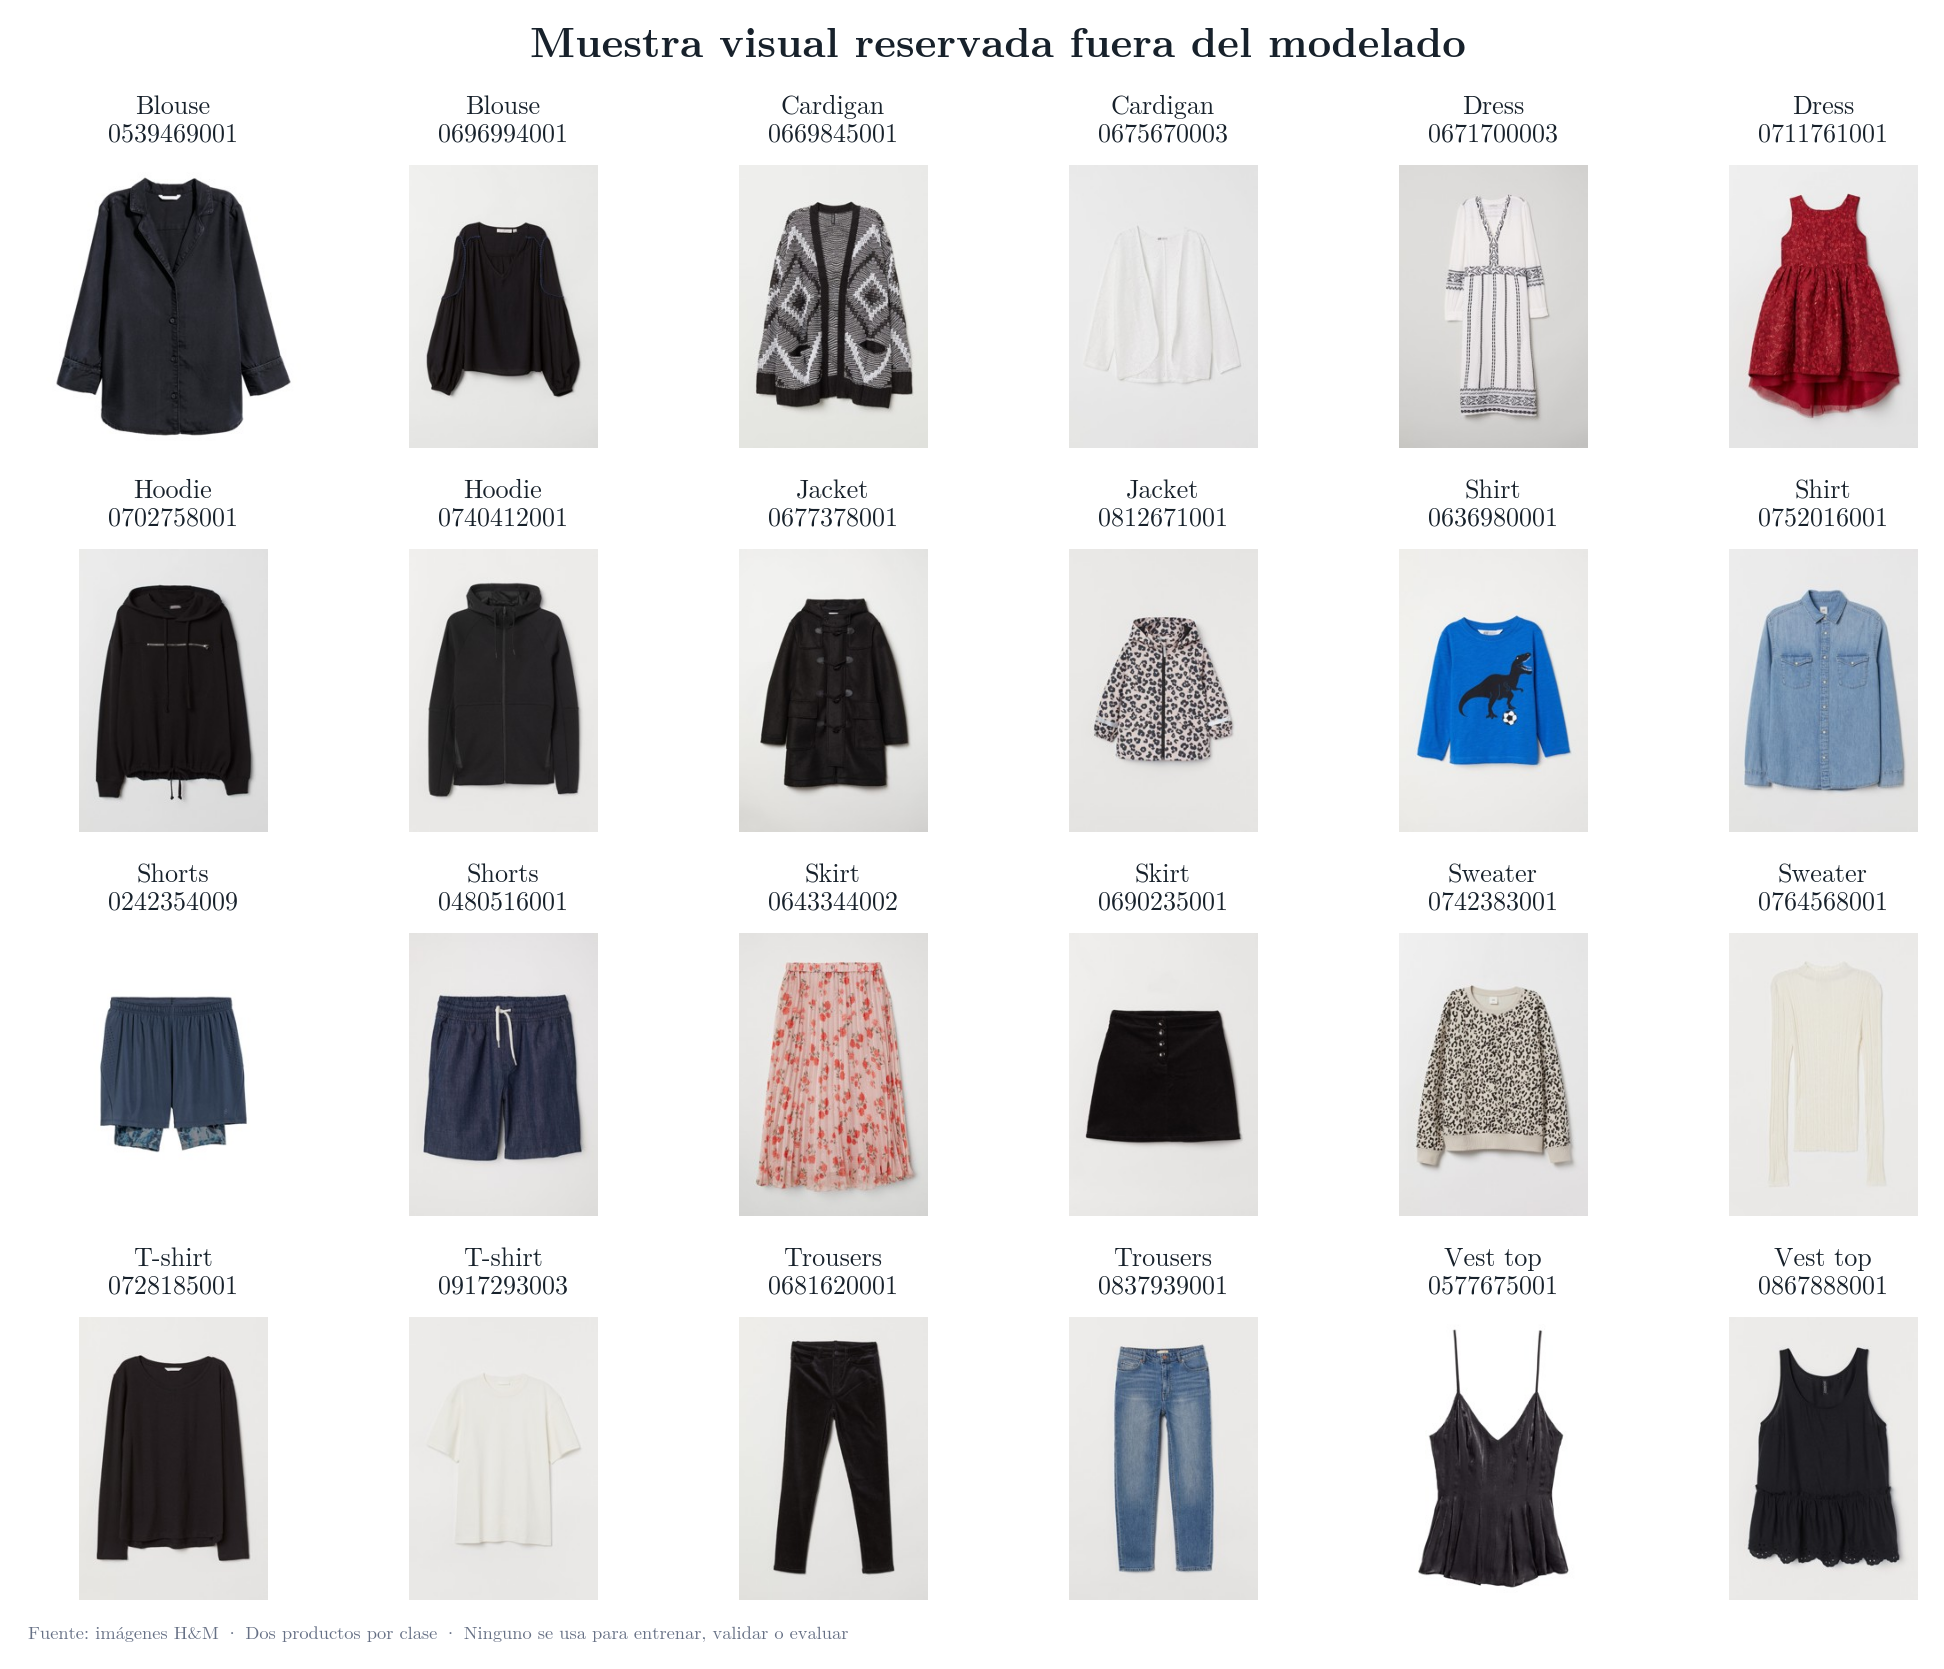

In [4]:
visual = selection.loc[selection.exclusion_reason.eq('visual_audit_group')].copy()
visual = visual.sort_values('article_id').drop_duplicates(['label', 'product_code']).groupby('label', sort=True).head(2)
assert set(visual.product_code).isdisjoint(candidates.product_code)
raw_base = Path(summary['raw_image_base'])
from notebook_utils import visual_thumbnail
fig, axes = plt.subplots(4, 6, figsize=(18, 15))
for ax, row in zip(axes.flat, visual.sort_values(['label', 'article_id']).itertuples()):
    ax.imshow(visual_thumbnail(row, raw_base, ROOT))
    ax.set_title(f'{row.label}\n{row.article_id}', fontsize=9, weight='normal')
for ax in axes.flat: ax.axis('off')
fig.suptitle('Muestra visual reservada fuera del modelado', weight='bold', fontsize=15, y=.98)
save_figure(fig, ROOT, '01_reserved_visual_audit', 'Fuente: imágenes H&M · Dos productos por clase · Ninguno se usa para entrenar, validar o evaluar')
plt.show()

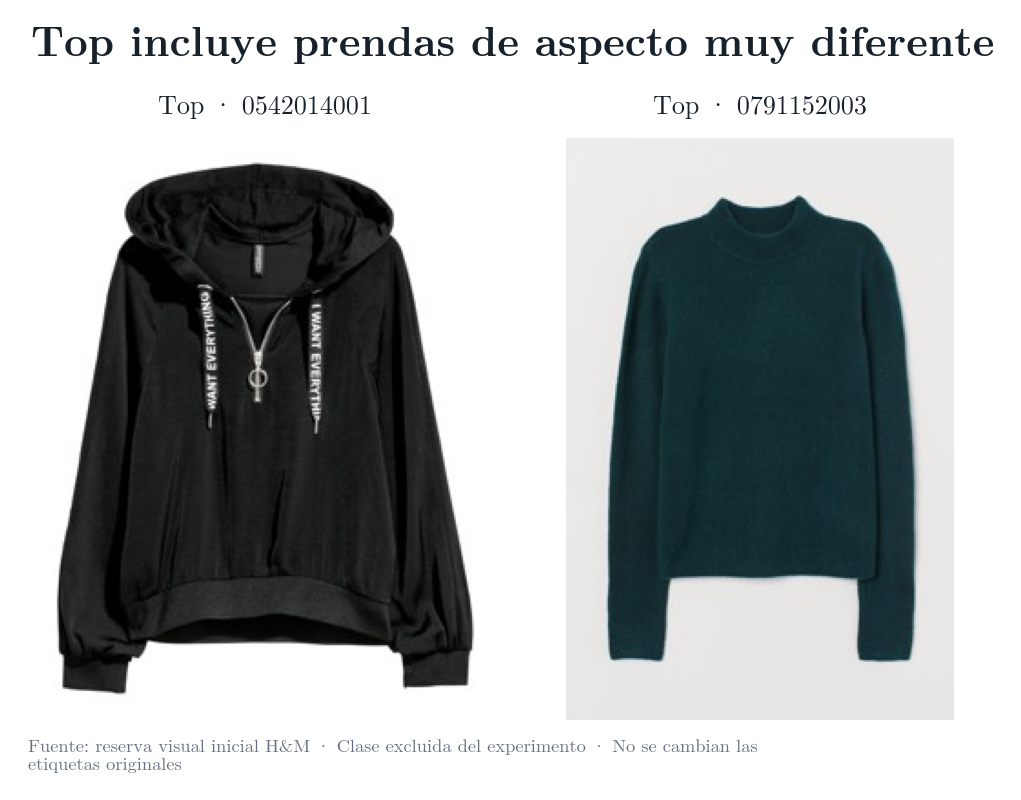

In [5]:
# Evidencia de la categoría descartada, siempre fuera del modelado.
from prepare_local import connect_groups
rejected = audit.loc[audit.article_id.isin(['0542014001', '0791152003'])].copy()
global_groups = connect_groups(valid, ['pixel_sha256'])
reserved_groups = global_groups.loc[valid.article_id.isin(rejected.article_id)]
related_ids = set(valid.loc[global_groups.isin(reserved_groups), 'article_id'])
assert related_ids.isdisjoint(candidates.article_id)
fig, axes = plt.subplots(1, 2, figsize=(9, 7))
for ax, row in zip(axes, rejected.itertuples()):
    ax.imshow(visual_thumbnail(row, raw_base, ROOT))
    ax.set_title(f'Top · {row.article_id}', fontsize=10, weight='normal')
    ax.axis('off')
fig.suptitle('Top incluye prendas de aspecto muy diferente', weight='bold', fontsize=15)
save_figure(fig, ROOT, '01_rejected_top_examples', 'Fuente: reserva visual inicial H&M · Clase excluida del experimento · No se cambian las etiquetas originales')
plt.show()

## 8. Decisiones que pasan al notebook 02

- Objetivo: `product_type_name`, con las doce clases explícitas de la configuración.
- Imágenes RGB de 224×224, proporción conservada, relleno blanco y JPEG calidad 90. Las versiones de menor resolución se derivarán de esta copia; resoluciones superiores exigirán recuperar el RAW.
- Hasta 1.500 imágenes por clase, conservando grupos de producto; no se usan muestreos independientes de fotografías que puedan separar variantes relacionadas.
- Train/validation/test aproximadamente 70/15/15 **por grupos**, no exactamente por imágenes. La distribución real se publicará.
- Duplicados exactos eliminados y grupos con etiquetas contradictorias excluidos; duplicados aproximados y errores sutiles de etiquetado siguen siendo limitaciones.
- Estadísticos de normalización y pesos calculados exclusivamente con entrenamiento en el notebook 02.
- RAW preservado hasta disponer de una copia externa verificada. La preparación local tendrá que funcionar sin él.

Estas son decisiones de diseño iniciales, no conclusiones sobre rendimiento. No se ha usado el test para seleccionar modelos. Las fuentes docentes consultadas son `PRDL_MLLB_Presentation_III_Learning_and_Evaluation.pptx` (especialmente diapositivas 35, 43–44 y 60–63) y `1. Notebook for DL Reports.pdf`, documentadas en `docs/requisitos-profesor.md`.

In [10]:
display(Markdown(f"**Resultado real de la auditoría:** {es(summary['images_valid'])} imágenes válidas, "
                 f"{es(summary['missing_images'])} artículos sin imagen y {es(summary['images_invalid'])} imágenes inválidas. "
                 f"Antes de preparar quedan {es(len(candidates))} candidatos en {es(candidates.label.nunique())} clases. "
                 "La publicación definitiva y sus comprobaciones se generan en el notebook 02."))

**Resultado real de la auditoría:** 105.100 imágenes válidas, 442 artículos sin imagen y 0 imágenes inválidas. Antes de preparar quedan 18.000 candidatos en 12 clases. La publicación definitiva y sus comprobaciones se generan en el notebook 02.